# code_111 · Feature attention and causal temporal attention

**Book:** section 22.4. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_111).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2311;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2311


<a id="token-contract"></a>
 ## Token meaning precedes the attention matrix
 Two independent tasks use an original one-block Transformer computation (multihead attention, residual paths, feature normalization and feedforward sublayer). A mixed-feature table uses per-field numerical embeddings, a category embedding and a learned summary token. A separate sensor forecaster uses time tokens, fixed sinusoidal positions and a causal mask. These are transparent small models trained from scratch, not execution of FT-Transformer defaults or a pretrained language model. Whole-building fitting/development/final splits remain separate for each task. Attention weights describe this fitted mixing calculation; they are not causal importance labels.


Table MSE: 0.15171040761103277 forecast MSE: 0.010172542691388434 persistence: 0.037192203709195557


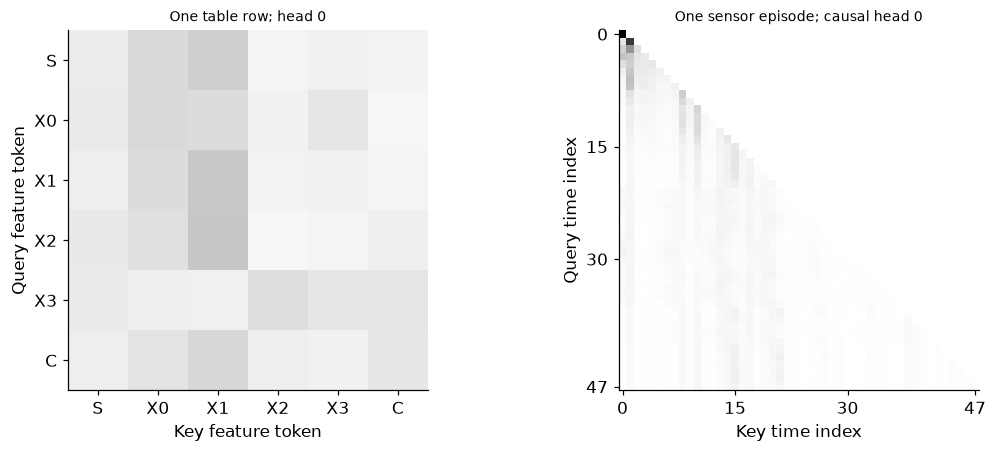

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
# One exact scaled-attention fixture, checked against the native primitive with an additive mask.
q=torch.tensor([[[1.,0.],[0.,1.],[1.,1.]]]);k=q.clone();v=torch.tensor([[[1.,0.],[0.,2.],[3.,1.]]]);forbidden=torch.triu(torch.ones(3,3,dtype=torch.bool),1);score=q@k.transpose(-1,-2)/np.sqrt(2);additive=torch.zeros(3,3).masked_fill(forbidden,-torch.inf);weights=torch.softmax(score+additive,dim=-1);manual=weights@v;native=nn.functional.scaled_dot_product_attention(q[:,None],k[:,None],v[:,None],attn_mask=additive,dropout_p=0.)[:,0]
torch.testing.assert_close(manual,native,atol=1e-12,rtol=1e-12);torch.testing.assert_close(weights.sum(-1),torch.ones(1,3));assert torch.max(weights.masked_select(forbidden[None]))==0
class Block(nn.Module):
    def __init__(self):
        super().__init__();self.norm1=nn.LayerNorm(8);self.attention=nn.MultiheadAttention(8,2,batch_first=True,dropout=0.);self.norm2=nn.LayerNorm(8);self.feedforward=nn.Sequential(nn.Linear(8,16),nn.GELU(),nn.Linear(16,8))
    def forward(self,z,attention_mask=None,padding_mask=None,return_weights=False):
        normalized=self.norm1(z);mixed,w=self.attention(normalized,normalized,normalized,attn_mask=attention_mask,key_padding_mask=padding_mask,need_weights=return_weights,average_attn_weights=False);h=z+mixed;return h+self.feedforward(self.norm2(h)),w
class FeatureModel(nn.Module):
    def __init__(self):
        super().__init__();self.numeric_weight=nn.Parameter(torch.randn(4,8)*.1);self.numeric_bias=nn.Parameter(torch.zeros(4,8));self.category=nn.Embedding(3,8);self.category_field=nn.Parameter(torch.zeros(1,8));self.summary=nn.Parameter(torch.zeros(1,1,8));self.block=Block();self.head=nn.Linear(8,1)
    def forward(self,values,category,return_weights=False):
        numeric=values[:,:,None]*self.numeric_weight+self.numeric_bias;categorical=(self.category(category)+self.category_field)[:,None,:];tokens=torch.cat([self.summary.expand(values.shape[0],-1,-1),numeric,categorical],1);h,w=self.block(tokens,return_weights=return_weights);return self.head(h[:,0]).squeeze(-1),w
building=np.repeat(np.arange(30),6);raw=rng.normal(size=(180,4))+.3*rng.normal(size=(30,4))[building];category=rng.integers(0,3,180);target=.8*np.sin(raw[:,0])+.6*raw[:,1]*raw[:,2]-.2*raw[:,3]+np.array([0.,.3,-.2])[category]+rng.normal(0,.1,180)
train=building<20;dev=(building>=20)&(building<25);final=building>=25;scaler=StandardScaler().fit(raw[train]);x=torch.tensor(scaler.transform(raw));cat=torch.tensor(category,dtype=torch.long);y=torch.tensor(target);torch.manual_seed(SEED);feature_model=FeatureModel();optimizer=torch.optim.AdamW(feature_model.parameters(),lr=.01,weight_decay=.001);best=float('inf')
for step in range(250):
    optimizer.zero_grad();prediction,_=feature_model(x[train],cat[train]);loss=torch.mean((prediction-y[train])**2);loss.backward();optimizer.step()
    if (step+1)%5==0:
        with torch.no_grad():prediction,_=feature_model(x[dev],cat[dev]);value=float(torch.mean((prediction-y[dev])**2))
        if value<best:best=value;state=copy.deepcopy(feature_model.state_dict());best_step=step+1
feature_model.load_state_dict(state);feature_model.eval()
with torch.no_grad():prediction,feature_weights=feature_model(x[final],cat[final],True);table_mse=float(torch.mean((prediction-y[final])**2))
assert feature_weights.shape==(30,2,6,6)
# A separate causal forecast: input at event t contains observed state_t and admitted load_t.
loads=rng.normal(size=(50,48));latent=np.zeros((50,49));phases=rng.uniform(0,2*np.pi,50)
for time_index in range(48):latent[:,time_index+1]=.85*latent[:,time_index]+.12*np.sin(.2*time_index+phases)+.15*loads[:,time_index]+rng.normal(0,.08,50)
observed=latent+rng.normal(0,.02,latent.shape);raw_time=np.stack([observed[:,:-1],loads],axis=-1);target_time=observed[:,1:];time_scaler=StandardScaler().fit(raw_time[:30].reshape(-1,2));time_x=torch.tensor(time_scaler.transform(raw_time.reshape(-1,2)).reshape(raw_time.shape));time_y=torch.tensor(target_time)
def positions(length,dtype):
    index=torch.arange(length,dtype=dtype)[:,None];scale=torch.exp(torch.arange(0,8,2,dtype=dtype)*(-np.log(10000)/8));angle=index*scale;out=torch.zeros(length,8,dtype=dtype);out[:,0::2]=torch.sin(angle);out[:,1::2]=torch.cos(angle);return out
class TemporalModel(nn.Module):
    def __init__(self):super().__init__();self.input=nn.Linear(2,8);self.block=Block();self.head=nn.Linear(8,1)
    def forward(self,values,causal=True,return_weights=False):
        length=values.shape[1];z=self.input(values)+positions(length,values.dtype);mask=torch.triu(torch.ones(length,length,dtype=torch.bool),1) if causal else None;h,w=self.block(z,mask,return_weights=return_weights);return self.head(h).squeeze(-1),w
torch.manual_seed(SEED+1);temporal=TemporalModel();optimizer=torch.optim.AdamW(temporal.parameters(),lr=.01,weight_decay=.001);best_time=float('inf')
for step in range(250):
    optimizer.zero_grad();prediction,_=temporal(time_x[:30]);loss=torch.mean((prediction-time_y[:30])**2);loss.backward();optimizer.step()
    if (step+1)%5==0:
        with torch.no_grad():prediction,_=temporal(time_x[30:40]);value=float(torch.mean((prediction-time_y[30:40])**2))
        if value<best_time:best_time=value;time_state=copy.deepcopy(temporal.state_dict());time_step=step+1
temporal.load_state_dict(time_state);temporal.eval()
with torch.no_grad():
    prediction,time_weights=temporal(time_x[40:],return_weights=True);forecast_mse=float(torch.mean((prediction-time_y[40:])**2));persistence_mse=float(np.mean((raw_time[40:,:,0]-target_time[40:])**2))
    probe=time_x[40:41].clone();changed=probe.clone();changed[:,24:]+=3;original,_=temporal(probe);perturbed,_=temporal(changed);torch.testing.assert_close(original[:,:24],perturbed[:,:24],atol=1e-12,rtol=1e-12)
    unmasked,_=temporal(probe,causal=False);unmasked_changed,_=temporal(changed,causal=False);prefix_difference=torch.abs(perturbed-original).numpy().ravel();unmasked_difference=torch.abs(unmasked_changed-unmasked).numpy().ravel()
    assert torch.max(torch.triu(time_weights[0,0],diagonal=1))==0
# Permutation and padding audits apply to the block without external positional additions.
torch.manual_seed(SEED+99);fixture=torch.randn(1,12,8);permutation=torch.tensor(rng.permutation(12));block=temporal.block.eval()
with torch.no_grad():
    base,_=block(fixture);permuted,_=block(fixture[:,permutation]);torch.testing.assert_close(permuted,base[:,permutation],atol=1e-12,rtol=1e-12)
    position=positions(12,fixture.dtype);with_position,_=block(fixture+position);moved_content,_=block(fixture[:,permutation]+position);position_difference=float(torch.max(torch.abs(moved_content-with_position[:,permutation])))
    padded=fixture[:,:6];padding=torch.tensor([[False,False,False,False,True,True]]);changed_padding=padded.clone();changed_padding[:,4:]+=5;a,pad_weights=block(padded,padding_mask=padding,return_weights=True);b,_=block(changed_padding,padding_mask=padding);torch.testing.assert_close(a[:,:4],b[:,:4],atol=1e-12,rtol=1e-12);assert torch.max(pad_weights[:,:,:,4:])==0
assert position_difference>1e-8
RESULTS.update(manual_attention=manual.numpy().tolist(),table_final_MSE=table_mse,table_development_MSE=best,table_best_step=best_step,table_split_buildings=[20,5,5],temporal_final_MSE=forecast_mse,temporal_development_MSE=best_time,temporal_best_step=time_step,persistence_final_MSE=persistence_mse,temporal_split_buildings=[30,10,10],causal_prefix_max_difference=float(prefix_difference[:24].max()),unmasked_prefix_max_difference=float(unmasked_difference[:24].max()),position_content_permutation_difference=position_difference,padding_valid_query_max_difference=float(torch.max(torch.abs(a[:,:4]-b[:,:4]))),feature_attention_shape=list(feature_weights.shape),time_attention_shape=list(time_weights.shape),materialized_score_bytes=[{'length':length,'batch':1,'heads':2,'float64_bytes':2*length*length*8} for length in [32,128,512]])
print('Table MSE:',table_mse,'forecast MSE:',forecast_mse,'persistence:',persistence_mse)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].imshow(feature_weights[0,0].numpy(),cmap='Greys',vmin=0,vmax=1);axes[0].set(title='One table row; head 0',xlabel='Key feature token',ylabel='Query feature token',xticks=range(6),yticks=range(6),xticklabels=['S','X0','X1','X2','X3','C'],yticklabels=['S','X0','X1','X2','X3','C'])
axes[1].imshow(time_weights[0,0].numpy(),cmap='Greys',vmin=0,vmax=1);axes[1].set(title='One sensor episode; causal head 0',xlabel='Key time index',ylabel='Query time index',xticks=[0,15,30,47],yticks=[0,15,30,47]);plt.show()


<a id="attention-limits"></a>
 ## Access is a model contract
 The table summary token S can mix every admitted feature token; numerical tokens retain field identity through their learned feature-specific weights and biases. The sensor token at time t can mix only keys through t. MHA boolean True masks forbid attention; the native scaled-attention identity instead uses an explicit additive zero/-infinity mask. Padding masks exclude keys, while padded queries still need a separate loss/output policy. Content-only self-attention is permutation-equivariant, and slot positions alter that behavior. These encoder-style and decoder-style self-attention roles do not constitute a full pretrained encoder–decoder system. Score-array bytes below are exact accounting for a materialized array, not measured process RSS or a claim that optimized kernels always materialize it.


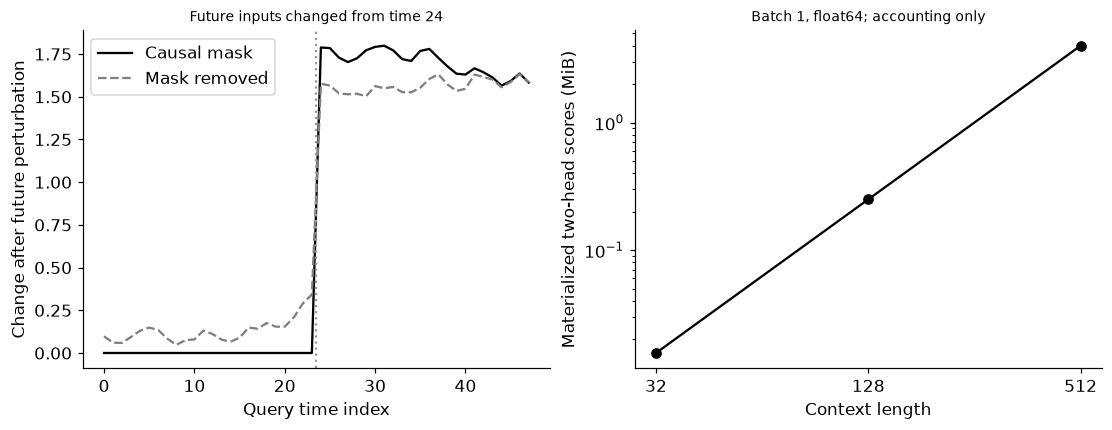

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8));axes[0].plot(prefix_difference,'-',color='black',label='Causal mask');axes[0].plot(unmasked_difference,'--',color='.5',label='Mask removed');axes[0].axvline(23.5,color='.6',linestyle=':');axes[0].set(xlabel='Query time index',ylabel='Change after future perturbation',title='Future inputs changed from time 24');axes[0].legend()
lengths_plot=[32,128,512];axes[1].loglog(lengths_plot,[2*length**2*8/1024**2 for length in lengths_plot],'o-',color='black');axes[1].set(xlabel='Context length',ylabel='Materialized two-head scores (MiB)',title='Batch 1, float64; accounting only');axes[1].set_xticks([32,128,512],labels=['32','128','512']);axes[1].xaxis.set_minor_locator(matplotlib.ticker.NullLocator());plt.show()
assert np.isfinite([table_mse,forecast_mse,persistence_mse]).all()


In [4]:
summary={'example_id':'code_111','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['scaled dot-product attention identity', 'actual multihead transformer blocks', 'feature versus time tokens', 'position and padding contracts', 'causal future-perturbation test'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["scaled dot-product attention identity", "actual multihead transformer blocks", "feature versus time tokens", "position and padding contracts", "causal future-perturbation test"], "elapsed_seconds": 1.975, "example_id": "code_111", "hardware": "Darwin arm64 CPU", "results": {"causal_prefix_max_difference": 0.0, "feature_attention_shape": [30, 2, 6, 6], "manual_attention": [[[1.0, 0.0], [0.33023845067334306, 1.3395230986533138], [1.7587246087113846, 1.0]]], "materialized_score_bytes": [{"batch": 1, "float64_bytes": 16384, "heads": 2, "length": 32}, {"batch": 1, "float64_bytes": 262144, "heads": 2, "length": 128}, {"batch": 1, "float64_bytes": 4194304, "heads": 2, "length": 512}], "padding_valid_query_max_difference": 0.0, "persistence_final_MSE": 0.037192203709195557, "position_content_permutation_difference": 1.716878836374487, "table_best_step": 250, "table_development_MSE": 0.04504705466703456, "table_final_MSE": 0.15171040761103277, 